# Comparing Regression Models

The aim of this exercise is to train five models: a Linear Regression model, two Polynomial Regression models, and two kNN regression models, then decide which performs best.

## 1. Import libraries

In [1]:
import operator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prettytable import PrettyTable
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

## 2. Load and inspect the dataset

Make sure `Credit.csv` is in the same folder as this notebook.

In [2]:
df = pd.read_csv("Credit.csv")
df.head()

,x,y
0,1.00,29.32
1,1.83,4.20
2,2.66,35.56
3,3.50,38.16
4,4.33,-14.66


## 3. Select predictor and response variables

In [3]:
# Predictor variable
x = df[['x']].values

# Response variable
y = df['y'].values

## 4. Split into training and testing sets

Use 75% of the data for training and 25% for testing.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.75, random_state=1
)

## 5. Train the five models and calculate test MSE

In [5]:
# Store test errors and model names
test_error = []
model_names = []

# Linear Regression
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
test_error.append(mse)
model_names.append('Linear Regression')

# Polynomial Regression (degrees 2 and 5)
degree_list = [2, 5]

for d in degree_list:
    poly = PolynomialFeatures(degree=d)
    X_train = poly.fit_transform(x_train)
    X_test = poly.transform(x_test)

    lreg = LinearRegression()
    lreg.fit(X_train, y_train)
    y_pred = lreg.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)

    test_error.append(mse)
    model_names.append(f'Polynomial Regression (degree {d})')

# kNN Regression (k = 1 and k = 20)
knn_list = [1, 20]

for k in knn_list:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    mse = mean_squared_error(y_test, y_pred)

    test_error.append(mse)
    model_names.append(f'kNN Regression (k={k})')

## 6. Compare the models

A lower MSE means the model's predictions were closer to the test values.

In [6]:
results = pd.DataFrame({
    'Model': model_names,
    'Test MSE': test_error
}).sort_values('Test MSE').reset_index(drop=True)

results

,Model,Test MSE
0,Polynomial Regression (degree 2),173.541973
1,Polynomial Regression (degree 5),175.264513
2,kNN Regression (k=1),437.370693
3,kNN Regression (k=20),454.226068
4,Linear Regression,773.669211


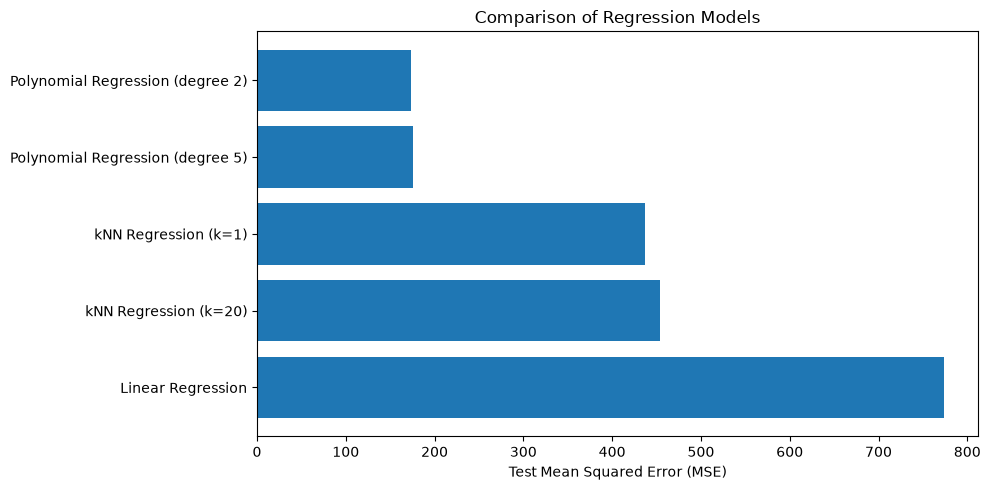

Best model: Polynomial Regression (degree 2)
Lowest test MSE: 173.54197268246787


In [7]:
plt.figure(figsize=(10, 5))
plt.barh(results['Model'], results['Test MSE'])
plt.xlabel('Test Mean Squared Error (MSE)')
plt.title('Comparison of Regression Models')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print('Best model:', results.loc[0, 'Model'])
print('Lowest test MSE:', results.loc[0, 'Test MSE'])